In [3]:
import numpy as np
import sympy as sym
from sympy import pprint
from scipy.sparse import csr_matrix as csr
from scipy.sparse import kron 

#numpy printoptions
# np.set_printoptions(precision=3, suppress=True)

In [21]:



def pp(M, rounding=3, imag_tolerance = 1e-12):
    if type(M) is not np.ndarray:
        print(M)
    else:
        M = M.real.round(rounding) + 1j*M.imag.round(rounding)
        if imag_tolerance is not None:
            M = np.where(np.abs(M.imag) < imag_tolerance, M.real, M)
        print(np.round(M, rounding))


def adj_line(q):            # function for creating adjacency matrix for a line graph of q vertices
    adj = np.zeros((q,q))
    for i in range(q):
        if i == 0:
            adj[i, i+1] = 1
        elif i == q-1:
            adj[i, i-1] = 1
        else:
            adj[i, i+1] = 1
            adj[i, i-1] = 1
    return adj


def sparse_to_dense(size, list, inv = False):       # list format : [[],[],[]] ...locations of ones
    l = len(list)
    s = size
    adj = np.zeros([s,s])
    # print(adj.shape)

    for i in list:
        adj[i[0], i[1]] = 1
        adj[i[1], i[0]] = 1

    if inv:
        adj = np.ones(s,s) - adj

    return adj



In [32]:
class QuantumSystem:
    def __init__(self, q, alpha = 'auto'):
        self.q = q      # q is the number of main qubits, there are extra q ancilla qubits . Total 2*q qubits
        self.N = 2**q
        self.alpha = alpha

        self.psi0_a = self.superposition_state()
        self.zero_b = self.superposition_state(coeffs = [1] + [0]*(self.N-1))
        self.psi_kron_0 = np.kron(self.psi0_a, self.zero_b)
        
        self.I_a = np.eye(self.N)
        self.I_b = np.eye(self.N)
        self.Proj_ab = np.kron(self.I_a, self.zero_b @ self.zero_b.conj().T)    # projection operator - Identity on a, projection on |0> on b
        
        self.Phase = np.diag(self.phase_operator_phases(alpha))                      # phase operator from the phases, "U_a" in notes
        self.Swap = self.U_ab()                                                 # swap operator, "U_ab" in notes
        
    def matrix_basis(self):
        q = self.q
        N = 2**q
        basis = []
        for i in range(N):
            state_i = np.zeros(N)
            state_i[i] = 1
            basis.append(state_i)
        return np.array(basis)

    def superposition_state(self, coeffs = 'maximal_except_0'):        # careful, dont include the zeros
        q = self.q
        N = self.N
        if coeffs == 'maximal_except_0':
            coeffs = np.ones(N)
            coeffs[0] = 0

        basis = self.matrix_basis()

        c = np.array(coeffs).reshape(1, N)
        c = c/np.sqrt(np.sum(np.abs(c)**2))  # normalizing 

        if basis.shape[1] != c.shape[1]:
            raise ValueError('Error: Shapes of coefficients and basis do not match')
        if len(coeffs) != N:            # checking length
            raise ValueError('Error: The number of coefficients is not 2^q')

        sup_state = np.sum(c * basis, axis = 1, keepdims = True)
        if (np.linalg.norm(sup_state)-1) > 1e-10:
            raise ValueError('Error: The resultant state is not normalized')
        return sup_state
    
    
    #defining the "partial swap" matrix for q qubits
    def U_ab(self):    
        q, N = self.q, self.N
        def kron_delta(a, b):
            return 1 if a == b else 0
        def U_mn(m,n):
            i, j = divmod(m, N)
            k, l = divmod(n, N)

            if k == 0 and l == 0:
                return (kron_delta(i, 0) * kron_delta(j, 0))
            elif k == 0 and l != 0:
                return (1/np.sqrt(2))*(kron_delta(i, 0) * kron_delta(j, l) - kron_delta(i, l) * kron_delta(j, 0))
            elif k != 0 and l == 0:
                return (1/np.sqrt(2))*(kron_delta(i, k) * kron_delta(j, 0) + kron_delta(i, 0) * kron_delta(j, k))
            else:
                return (kron_delta(i, k) * kron_delta(j, l))

        U = np.zeros((N**2, N**2))
        for m in range(N**2):       # create matrix using for loops - numpy gives errors
            for n in range(N**2):
                U[m, n] = U_mn(m, n)
        return U


    def phase_operator_phases(self, alpha = 'auto'):       # phases for the phase operator
        q, N = self.q, self.N
        # alpha is the coefficient in the Hamiltonian
        if q%2 == 0:            # creating alpha automatically, see notebook
            alpha = 4*np.pi/q**2
        else:
            alpha = 4*np.pi/(q**2-1)
        if alpha != 'auto':
            alpha = alpha           

        def qubit_sequence(a,q):
            b = np.binary_repr(a, width = q)       # string
            c = np.array([int(i) for i in b])   # array
            return c

        def edges_count(seq):   #seq is a binary sequence array
            p_0 = np.count_nonzero(seq == 0)
            p_1 = np.count_nonzero(seq == 1)
            return int(p_0*p_1)

        phases = []
        for i in range(N):
            cross_edges_i = edges_count(qubit_sequence(i, q)) 
            phase_i = np.exp(-1j*alpha*cross_edges_i)
            phases.append(phase_i)
        
        return np.array(phases)
        



In [46]:
Q2 = QuantumSystem(2)

pp(Q2.Phase,1)


# np.eye(4)


⎡1.0   0     0     0 ⎤
⎢                    ⎥
⎢ 0   -1.0   0     0 ⎥
⎢                    ⎥
⎢ 0    0    -1.0   0 ⎥
⎢                    ⎥
⎣ 0    0     0    1.0⎦


In [25]:
import numpy as np

# Given adjacency matrix
graph = np.array([
    [0, 1, 1, 0],  # A
    [1, 0, 0, 1],  # B
    [1, 0, 0, 1],  # C
    [0, 1, 1, 0]   # D
])

# Use np.where to get indices where the value is 1
indices = np.where(graph < 2)

# Stack the row and column indices to create a list of tuples
indices_of_ones = np.stack(indices, axis=-1)

# print(indices_of_ones)

indices_of_ones.shape


ValueError: operands could not be broadcast together with shapes (16,2) (4,4) 

In [15]:
print(indices_of_ones)

[[0 0]
 [0 1]
 [0 2]
 [0 3]
 [1 0]
 [1 1]
 [1 2]
 [1 3]
 [2 0]
 [2 1]
 [2 2]
 [2 3]
 [3 0]
 [3 1]
 [3 2]
 [3 3]]


In [26]:
per = np.array([1,0,1,0,1,1])
# create arrays having indices of 1s and 0s
ones =  np.array(np.where(per == 1))
zeros = np.array(np.where(per == 0))
ones.shape
# array having cartesian product of 1s and 0s elements
# cartesian_product = np.array(np.meshgrid(ones, zeros))
# cartesian_product

(1, 4)

In [33]:
arr = np.array([[0, 2, 3], [4, 5, 6], [7, 8, 9]])

a = arr.copy()



In [38]:
# a[a < 5] += 10
b = np.where(a > -10)

b

(array([0, 0, 0, 1, 1, 1, 2, 2, 2]), array([0, 1, 2, 0, 1, 2, 0, 1, 2]))

In [3]:
import numpy as np
qubit_string = '101'
qubit_perm = np.array([int(i) for i in qubit_string])

qubit_perm[qubit_perm == 0] = -1

col_indices, row_indices = np.meshgrid(qubit_perm, qubit_perm)  # eg. for permutation 101, col_indices will have columns 1,0 and 1; row_indices will have rows 1,0 and 1. Multiplying these will give only the cross edges to be 0, remaining will be 1. 

cross_edges_raw = col_indices * row_indices
cross_edges_ut_raw = np.triu(cross_edges_raw, k = 1)        # upper triangular part of the matrix to avoid double counting
cross_edges_ut_raw[cross_edges_ut_raw == 1] = 0             # inverting, to change cross edges from 0 to -1 (and latter to 1)
cross_edges = (-1)*cross_edges_ut_raw                       # changing cross edges from -1 to 1

cross_edges_count = np.sum(cross_edges)

cross_edges ,cross_edges_count



(array([[0, 1, 0],
        [0, 0, 1],
        [0, 0, 0]]),
 2)

In [6]:
import numpy as np

def adjacency_to_edge_array(adj_matrix):
    """
    Converts an adjacency matrix to a 2D NumPy array of edges.
    """
    origin, destination = np.nonzero(adj_matrix)
    edge_array = np.vstack((origin, destination)).T
    
    return edge_array           # number of rows are twice the number of edges coz of repetition



adj_sq = np.array([[0, 1, 1, 0], [1, 0, 0, 1], [1, 0, 0, 1], [0, 1, 1, 0]])



array([[0, 1],
       [0, 2],
       [1, 0],
       [1, 3],
       [2, 0],
       [2, 3],
       [3, 1],
       [3, 2]])

In [60]:
y = np.ones((4,5)) 
x = 2* np.ones(4).reshape(1,4)
x[0,2] = 3

print((x.T)*y)

# print(x @ y)

(x.T[2:] - .5)

np.diag(x)


[[2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2.]
 [3. 3. 3. 3. 3.]
 [2. 2. 2. 2. 2.]]


array([2.])

In [11]:
import numpy as np
x, y = [5,1], [[1,1],[2,3]]

x, y = np.array(x), np.array(y)

x = x.reshape(2,1)
# x.shape
# print(y.shape)
# print(y[0])
print(x*y)

[[5 5]
 [2 3]]


In [ ]:
q = 3
adj_matrix = np.array([[0,1,0], [1,0,1], [0,1,0]])

Q3 = QuantumSystem(q, adj_matrix)



In [6]:
# circumveniting Swap matrices by using analytical expressions

import numpy as np
class QuantumSystem:
    def __init__(self, q, adj_matrix):
        self.q = q      # q is the number of main qubits, there are extra q ancilla qubits . Total 2*q qubits
        self.N = 2**q
        
        self.adj_matrix = adj_matrix
        self.E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph
        self.alpha = -np.pi/(2*self.E_t)
        
        #Cached variables
        self.cached_basis_states = None
        self.cached_psi0 = None
        self.cached_zero = None
        self.cached_psi0_tensor_zero = None
        self.cached_I_a =  None
        self.cached_Proj_ab = None
        self.cached_phase_list = None
        # self.cached_Phase = None
        # self.cached_Swap = None
        self.cached_U_big = None
        
        self.cached_prob1 = None
        self.cached_prob2 = None
        self.cached_psi_iter2 = None
        

    # instead of defining a method for creating matrix basis we will do it as a class variable
    @property
    def Identity_N(self):
        if self.cached_basis_states is None:
            self.cached_basis_states = np.eye(self.N)
        return self.cached_basis_states         # returns identity matrix of size 2^q = N
        
    @property
    def psi0(self):
        if self.cached_psi0 is None:
            self.cached_psi0 = (1/np.sqrt(self.N-1))*np.sum(self.Identity_N[1:], axis = 0, keepdims = True).T
        return self.cached_psi0
    
    @property
    def zero(self):
        if self.cached_zero is None:
            self.cached_zero = np.eye(self.N)[0].reshape(1, self.N).T
        return self.cached_zero

    @property
    def psi0_tensor_zero(self):
        if self.cached_psi0_tensor_zero is None:
            self.cached_psi0_tensor_zero = np.kron(self.psi0, self.zero)
        return self.cached_psi0_tensor_zero

    @property
    def Proj_ab(self):
        if self.cached_Proj_ab is None:
            self.cached_Proj_ab = np.kron(self.Identity_N, self.zero @ self.zero.conj().T)  # projection operator
        return self.cached_Proj_ab

    @property
    def phase_angles(self):
        if self.cached_phase_list is None:
            self.cached_phase_list = self.phases(self.q, self.adj_matrix).reshape(self.N, 1)     
        return self.cached_phase_list           # COLUMN of phases ANGLES

    @property
    def phase_list(self):       # column of phases (not angles)
        return np.exp(1j*self.phase_angles)
    
    
    @property
    def Phase(self):        # phase operator
        return np.diag(np.exp(1j*self.phase_angles.reshape(-1)))

    @property
    def p1(self):
        if self.cached_prob1 is None:
            self.cached_prob1 = (.25/(self.N-1))*((np.abs(self.phase_list[1:] - 1)**2).sum())
        return self.cached_prob1

    @property
    def p2(self):
        if self.cached_prob2 is None:
            self.cached_prob2 = (.25/((self.N-1)*self.p1))*((np.abs(self.phase_list[1:] - 1)**4).sum())
        return self.cached_prob2
    
    @property
    def psi_iter2(self):
        if self.cached_psi_iter2 is None:
            norm_coeff = 1/np.sqrt(4*(self.N -1)*self.p1*self.p2)
            psi_iter_2_a = norm_coeff*(((((self.phase_list[1:] - 1))**2)*self.Identity_N[1:]).sum(axis = 0, keepdims = True)).T
            self.cached_psi_iter2 = np.kron(psi_iter_2_a, self.zero)                        # projection/collapse on ancilla's zero state
        return self.cached_psi_iter2

    @property
    def Swap(self):
        return self.U_ab()  
    
    @property
    def U_big(self):
        if self.cached_U_big is None:
            self.cached_U_big = self.Swap @ (np.kron(self.Phase, self.Identity_N)) @ self.Swap
        return self.cached_U_big

    #defining the "partial swap" matrix for q qubits
    def U_ab(self):    
        q, N = self.q, self.N
        def kron_delta(a, b):
            return 1 if a == b else 0
        def U_mn(m,n):
            i, j = divmod(m, N)
            k, l = divmod(n, N)

            if k == 0 and l == 0:
                return (kron_delta(i, 0) * kron_delta(j, 0))
            elif k == 0 and l != 0:
                return (1/np.sqrt(2))*(kron_delta(i, 0) * kron_delta(j, l) - kron_delta(i, l) * kron_delta(j, 0))
            elif k != 0 and l == 0:
                return (1/np.sqrt(2))*(kron_delta(i, k) * kron_delta(j, 0) + kron_delta(i, 0) * kron_delta(j, k))
            else:
                return (kron_delta(i, k) * kron_delta(j, l))

        U = np.zeros((N**2, N**2))
        for m in range(N**2):       # create matrix using for loops - numpy gives errors
            for n in range(N**2):
                U[m, n] = U_mn(m, n)
        return U

    # defining the phase operator after defining the phi_x function for an phase of an individual permutation/basis state

    @staticmethod
    def qubit_sequence(x, q):
        b = np.binary_repr(x, width = q)       # binary string for the integer/basis state x (out of 2**q states) 
        c = np.array([int(i) for i in b])       # eg. '101' -> [1, 0, 1]
        return c
    # permut_arr is the array for the basis state x (which is a permutation of q qubits)
    @staticmethod
    def cross_edges_max_arr(permut_arr):             #all possible cross edges for this permutation (will add graph adjacency matrix later)
        permut_arr[permut_arr == 0] = -1            # calling the zeroes as -1, for distinguishing the cross edges upon multiplication
        col_indices, row_indices = np.meshgrid(permut_arr, permut_arr)  # eg. for permutation 101, col_indices will have columns 1,-1 and 1; row_indices will have rows 1,-1 and 1.

        CE_raw = col_indices * row_indices      # cross edges are -1, rest are 1
        CE_raw = np.triu(CE_raw, k = 1)        # upper triangular part of the matrix to avoid double counting
        CE_raw[CE_raw == 1] = 0             # inverting, to change cross edges from 0 to -1 (and latter to 1)
        cross_edge_arr = (-1)*CE_raw                       # changing cross edges from -1 to 1
        return cross_edge_arr                    # returns upper triangular array of 1 and 0s, 1 for cross edge, 0 for self edge or no edge
    
    def phi_x(self, x, q, adj):                 # returns the angle phi for the basis state/partition x
        """ Returns phi and alpha for the particular basis state/partition x, given the adjacency matrix of the graph."""
        partition_string = self.qubit_sequence(x, q)
        partition_string_copy = partition_string.copy()

        C_E_max_arr_x = self.cross_edges_max_arr(partition_string_copy)
        total_edges = np.sum(adj) / 2  # adj is the adjacency matrix of the given graph
        C_E_actual = C_E_max_arr_x * adj
        C_E_count = np.sum(C_E_actual)
        alpha = -np.pi / (2 * total_edges)
        phi = -2 * alpha * C_E_count
        return phi

    def phases(self, q, adj_matrix):        # runs phi_x for all basis states/partitions; returns the list of phase ANGLES, NOT exponential of them, for the whole basis
        N = 2**q
        E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph 
        phase_list = []
        for i in range(N):
            phase_list.append(self.phi_x(i, q, adj_matrix))
        phases = np.array(phase_list)
        return phases

    @staticmethod
    def norm_sq(state):        # returns sum of absolute squares ie. sum of probabilities
        return (np.abs(state)**2).sum()
    
    @staticmethod
    def normalize(state):           # normalizes the state
        if type(state) is not np.ndarray:
            raise ValueError('Error: State is not a numpy array')
        return (1/np.sqrt(QuantumSystem.norm_sq(state)))*state
    
    # @staticmethod
    # def tensor_div(arr,b):            # arr is tenosr prod of two states, b is the second state with all zeroes except one 1 at b'th position
    #     arr_copy = arr.copy()
    # @staticmethod
    # def state_to_qubit:


In [ ]:
q = 3 
adj_matrix = np.array([[0,1,0], [1,0,1], [0,1,0]])

Q3 = QuantumSystem(q, adj_matrix)

phases = Q3.phases(q, adj_matrix)
print(phases)                               # potentially, we can subtract the mode of the phases from all the phases to get a sparses set of phases

[0.         1.57079633 3.14159265 1.57079633 1.57079633 3.14159265
 1.57079633 0.        ]


In [ ]:
N = 2**q


I_N = csr(np.eye(N))
phase_list = Q3.phase_list
phases = Q3.phases(q, adj_matrix)
p1 = Q3.p1
p2 = Q3.p2
phases


array([0.        , 1.57079633, 3.14159265, 1.57079633, 1.57079633,
       3.14159265, 1.57079633, 0.        ])

In [ ]:
# print(type(I_N))
# I_N.toarray()

q = (1/2)*(1/np.sqrt(N*p1*p2))
basis_sum = (I_N[1:]).sum(axis = 0).T   #column


ph_sq = ((phase_list[1:] - 1)**2)
ph_sq = np.insert(ph_sq,0,1)


psi_iter_2_a = q*(ph_sq*np.array(basis_sum).reshape(-1))


# print(type(ph_sq), type(basis_sum.reshape(-1)))
print(psi_iter_2_a)
# ph_sq.shape, basis_sum.shape



[ 0.00000000e+00+0.00000000e+00j -2.99794481e-17-2.70030862e-01j
  5.40061725e-01-6.61384863e-17j -2.99794481e-17-2.70030862e-01j
 -2.99794481e-17-2.70030862e-01j  5.40061725e-01-6.61384863e-17j
 -2.99794481e-17-2.70030862e-01j  0.00000000e+00+0.00000000e+00j]


In [24]:
psi_iter_2_a.shape

(8, 7)

In [22]:
x = np.ones(5)
y = np.ones(5)

xx = x.reshape(1,5)
xx.shape, y.shape

xxx = xx.reshape(-1)


(5,)

In [ ]:
# analytical, extending to nth iteration

import numpy as np
class QuantumSystem:
    def __init__(self, q, adj_matrix):
        self.q = q      # q is the number of main qubits, there are extra q ancilla qubits . Total 2*q qubits
        self.N = 2**q
        
        self.adj_matrix = adj_matrix
        self.E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph
        self.alpha = -np.pi/(2*self.E_t)
        
        #Cached variables
        self.cached_basis_states = None
        self.cached_psi0 = None
        self.cached_zero = None
        self.cached_psi0_tensor_zero = None
        self.cached_I_a =  None
        self.cached_Proj_ab = None
        self.cached_phase_list = None
        # self.cached_U_big = None
        
        self.cached_probs = {0:1 }


        ###########
        self.cached_AbsSq_phase_minus_1 = self.abs_phase_minus_1()
        self.cached_probs = {0:1}                                       # list of probs for mth iter (not prod of probs)
        ###########
        self.cached_prob1 = None
        self.cached_prob2 = None
        self.cached_psi_iter2 = None
        

    # instead of defining a method for creating matrix basis we will do it as a class variable
    @property
    def Identity_N(self):
        if self.cached_basis_states is None:
            self.cached_basis_states = np.eye(self.N)
        return self.cached_basis_states         # returns identity matrix of size 2^q = N
        
    @property
    def psi0(self):
        if self.cached_psi0 is None:
            self.cached_psi0 = (1/np.sqrt(self.N-1))*np.sum(self.Identity_N[1:], axis = 0, keepdims = True).T
        return self.cached_psi0
    
    @property
    def zero(self):
        if self.cached_zero is None:
            self.cached_zero = np.eye(self.N)[0].reshape(1, self.N).T
        return self.cached_zero

    @property
    def psi0_tensor_zero(self):
        if self.cached_psi0_tensor_zero is None:
            self.cached_psi0_tensor_zero = np.kron(self.psi0, self.zero)
        return self.cached_psi0_tensor_zero

    @property
    def Proj_ab(self):
        if self.cached_Proj_ab is None:
            self.cached_Proj_ab = np.kron(self.Identity_N, self.zero @ self.zero.conj().T)  # projection operator
        return self.cached_Proj_ab

    @property
    def phase_angles(self):
        if self.cached_phase_list is None:
            self.cached_phase_list = self.phases(self.q, self.adj_matrix).reshape(self.N, 1)
        return self.cached_phase_list           # COLUMN of phases ANGLES

    @property
    def phase_list(self):       # column of phases (not angles)
        return np.exp(1j*self.phase_angles)
    
    @property
    def Phase(self):        # phase operator
        return np.diag(np.exp(1j*self.phase_angles.reshape(-1)))

    @property
    def p1(self):
        if self.cached_prob1 is None:
            self.cached_prob1 = (.25/(self.N-1))*((np.abs(self.phase_list[1:] - 1)**2).sum())
        return self.cached_prob1

    @property
    def p2(self):
        if self.cached_prob2 is None:
            self.cached_prob2 = ((1/16)/((self.N-1)*self.p1))*((np.abs(self.phase_list[1:] - 1)**4).sum())
        return self.cached_prob2


    def prob_m(self, m):
        if not m:
            return 1

        def prod_prob_m(m):
            if m == 0:
                return 1
            if m in self.cached_probs:              # using cached values recursively, if they exist in the dictionary
                return self.cached_probs[m]*prod_prob_m(m-1)
            
            p_minus_1 = prod_prob_m(m-1) 
            p = (1/((self.N-1)*(4**m)*p_minus_1))* np.sum(((self.cached_AbsSq_phase_minus_1)**m))   # mth prob
            self.cached_probs[m] = p                                            # caching the value of mth prob (not product prob)
            
            return p*p_minus_1

        prod_prob_m(m)
        p_m = self.cached_probs[m]                                              # 
        return p_m
    

    def abs_phase_minus_1(self):           # calc list from ONE to N of abs sq of e^(i*phi) -1. Done for efficiency 
        phases_from1 = np.array(self.phase_list.reshape(-1)[1:])
        phases_diff_abs_sq_from1 = np.abs(phases_from1-1)**2             # (e**i*phi -1)**2 for all except the first elt. len = 2**q -1
        return phases_diff_abs_sq_from1

    
    def psi_iter_m(self,m):
        if m not in self.cached_probs:
            self.prob_m(m)
        
        prod_probs_m = 1
        for i in range(m+1):                    # product of probs from 0 to m (m+1 not included)
            prod_probs_m *= self.cached_probs[i]

        denominator = (2**m)* np.sqrt((self.N-1)* prod_probs_m)

        phases = self.phase_list.reshape(-1)        # phases (not angles). Including the first one coz it is zero anyways, but will affect binary representation
        sum_qm_states = np.power(phases-1, m)        #quantum state except the prefactor

        return (1/denominator)*sum_qm_states    

    @property
    def Swap(self):
        return self.U_ab()  
    
    @property
    def U_big(self):
        if self.cached_U_big is None:
            self.cached_U_big = self.Swap @ (np.kron(self.Phase, self.Identity_N)) @ self.Swap
        return self.cached_U_big

    #defining the "partial swap" matrix for q qubits
    def U_ab(self):    
        q, N = self.q, self.N
        def kron_delta(a, b):
            return 1 if a == b else 0
        def U_mn(m,n):
            i, j = divmod(m, N)
            k, l = divmod(n, N)

            if k == 0 and l == 0:
                return (kron_delta(i, 0) * kron_delta(j, 0))
            elif k == 0 and l != 0:
                return (1/np.sqrt(2))*(kron_delta(i, 0) * kron_delta(j, l) - kron_delta(i, l) * kron_delta(j, 0))
            elif k != 0 and l == 0:
                return (1/np.sqrt(2))*(kron_delta(i, k) * kron_delta(j, 0) + kron_delta(i, 0) * kron_delta(j, k))
            else:
                return (kron_delta(i, k) * kron_delta(j, l))

        U = np.zeros((N**2, N**2))
        for m in range(N**2):       # create matrix using for loops - numpy gives errors
            for n in range(N**2):
                U[m, n] = U_mn(m, n)
        return U

    # defining the phase operator after defining the phi_x function for an phase of an individual permutation/basis state

    @staticmethod
    def qubit_sequence(x, q):
        b = np.binary_repr(x, width = q)       # binary string for the integer/basis state x (out of 2**q states) 
        c = np.array([int(i) for i in b])       # eg. '101' -> [1, 0, 1]
        return c
    # permut_arr is the array for the basis state x (which is a permutation of q qubits)
    @staticmethod
    def cross_edges_max_arr(permut_arr):             #all possible cross edges for this permutation (will add graph adjacency matrix later)
        permut_arr[permut_arr == 0] = -1            # calling the zeroes as -1, for distinguishing the cross edges upon multiplication
        col_indices, row_indices = np.meshgrid(permut_arr, permut_arr)  # eg. for permutation 101, col_indices will have columns 1,-1 and 1; row_indices will have rows 1,-1 and 1.

        CE_raw = col_indices * row_indices      # cross edges are -1, rest are 1
        CE_raw = np.triu(CE_raw, k = 1)        # upper triangular part of the matrix to avoid double counting
        CE_raw[CE_raw == 1] = 0             # inverting, to change cross edges from 0 to -1 (and latter to 1)
        cross_edge_arr = (-1)*CE_raw                       # changing cross edges from -1 to 1
        return cross_edge_arr                    # returns upper triangular array of 1 and 0s, 1 for cross edge, 0 for self edge or no edge
    
    def phi_x(self, x, q, adj):                 # returns the angle phi for the basis state/partition x
        """ Returns phi and alpha for the particular basis state/partition x, given the adjacency matrix of the graph."""
        partition_string = self.qubit_sequence(x, q)
        partition_string_copy = partition_string.copy()

        C_E_max_arr_x = self.cross_edges_max_arr(partition_string_copy)
        total_edges = np.sum(adj) / 2  # adj is the adjacency matrix of the given graph
        C_E_actual = C_E_max_arr_x * adj
        C_E_count = np.sum(C_E_actual)
        alpha = -np.pi / (2 * total_edges)
        phi = -2 * alpha * C_E_count
        return phi

    def phases(self, q, adj_matrix):        # runs phi_x for all basis states/partitions; returns the list of PHASES angles, NOT exponential of them, for the whole basis
        N = 2**q
        E_t = np.sum(adj_matrix)/2      # total number of edges in the given graph 
        phase_list = []
        for i in range(N):
            phase_list.append(self.phi_x(i, q, adj_matrix))
        phases = np.array(phase_list)
        return phases

    @staticmethod
    def norm_sq(state):        # returns sum of absolute squares ie. sum of probabilities
        return (np.abs(state)**2).sum()
    
    @staticmethod
    def normalize(state):           # normalizes the state
        if type(state) is not np.ndarray:
            raise ValueError('Error: State is not a numpy array')
        return (1/np.sqrt(QuantumSystem.norm_sq(state)))*state
    
    @staticmethod
    def sorted_binaries(arr, q = None):
        l = len(arr)
        width = int(np.log2(len(arr)))

        if not q :
            cut_off = l
        else:
            cut_off = int(2**q)

        l = np.array(arr).reshape(-1)             # arr is the amplified state (list/np array)
        l_abs_sq = np.abs(l)**2

        en_l = sorted(list(enumerate(l_abs_sq)), reverse = True, key = lambda x: x[1])[:cut_off]   #keeping on the best partitions
        en_binaries = [(format(i[0], '>0'+str(width)+'b'), i[1]) for i in en_l]

        return en_binaries
    

    @staticmethod
    def G_theta_hist(phases):
        import matplotlib.pyplot as plt
        """
        Plots histogram of phases with frequencies.
        Args:
        - phases (list or np.ndarray): List of phase angles in radians.
        - bins_ratio (int): Divide total phases length by this to calculate bins.
        Returns:
        - bins (np.ndarray): Bin edges.
        - freq (np.ndarray): Frequencies in each bin.
        """
        leng = len(phases)
        q = int(np.log2(leng)//1)
        num_bins = max(1, 8*2**(q//4))//1
        phase_range = (min(phases), max(phases))
    
        plt.hist(phases, bins=num_bins, range = phase_range, alpha=0.7, edgecolor='black')
    
        plt.xlabel(r"Phase ($\theta$)", fontsize=14)
        plt.ylabel(r"g($\theta$)", fontsize=14)
        plt.title("Phase Histogram")
        
        plt.grid(alpha=0.3)
        plt.show()
        return 0
"""
    @staticmethod
    def cumulative_states(phases, bins, freq, start, end):
        
        # Cumulative count of states between start and end phase angles.
        # Args:
        # - phases (list or np.ndarray): List of phase angles in radians.
        # - bins (np.ndarray): Bin edges from histogram.
        # - freq (np.ndarray): Frequencies from histogram.
        # - start (float): Start of angle range (in radians).
        # - end (float): End of angle range (in radians).
        # Returns:
        # - count (int): Cumulative number of states in the specified range.

        if start > end:
            raise ValueError("Start angle must be less than end angle.")
        
        start_bin = None
        end_bin = None
        for i in range(len(bins) - 1):
            if bins[i] <= start < bins[i + 1]:
                start_bin = i
            if bins[i] < end <= bins[i + 1]:
                end_bin = i

        if start_bin is None or end_bin is None:
            raise ValueError("Specified interval is outside the range of phases.")
        
        return sum(freq[start_bin:end_bin + 1])


"""




'\n    @staticmethod\n    def cumulative_states(phases, bins, freq, start, end):\n        \n        # Cumulative count of states between start and end phase angles.\n        # Args:\n        # - phases (list or np.ndarray): List of phase angles in radians.\n        # - bins (np.ndarray): Bin edges from histogram.\n        # - freq (np.ndarray): Frequencies from histogram.\n        # - start (float): Start of angle range (in radians).\n        # - end (float): End of angle range (in radians).\n        # Returns:\n        # - count (int): Cumulative number of states in the specified range.\n\n        if start > end:\n            raise ValueError("Start angle must be less than end angle.")\n        \n        start_bin = None\n        end_bin = None\n        for i in range(len(bins) - 1):\n            if bins[i] <= start < bins[i + 1]:\n                start_bin = i\n            if bins[i] < end <= bins[i + 1]:\n                end_bin = i\n\n        if start_bin is None or end_bin is None

In [ ]:
# for a 2D net of 9 qubits
q = 9

adj = np.array([[0, 1, 0 ,1, 0, 0, 0, 0, 0], [ 1,0,1,0,1,0,0,0,0], [0,1,0,0,0,1,0,0,0], [1,0,0,0,1,0,1,0,0], [0,1,0,1,0,1,0,1,0], [0,0,1,0,1,0,0,0,1], [0,0,0,1,0,0,0,1,0], [0,0,0,0,1,0,1,0,1], [0,0,0,0,0,1,0,1,0]])

Q9 = QuantumSystem(q, adj)

print(Q9.phase_list.reshape(-1).shape, 'wow')
p1,p2 = Q9.p1, Q9.p2
prob1, prob2, prob3, prob4 = Q9.prob_m(1), Q9.prob_m(2), Q9.prob_m(3), Q9.prob_m(4)

print('p1,2', p1, p2)
print('prob1,2', prob1, prob2)
print('prob3,4', prob3, prob4)


ff = Q9.psi_iter2.T
ff_w = np.where(abs(ff) > .07)
print(ff_w[1][:10])                          # indices with high amplitude

partitions = np.array([format(i, '018b') for i in ff_w[1]])
partitions_a = np.array([ i[0:9] for i in partitions])

partitions_prob_pair_list = zip( ff[0,ff_w[1]], partitions_a)     # working for q = 9, line graph
p = sorted(partitions_prob_pair_list, reverse = True)
p[:10]


(512,) wow
p1,2 0.5009784735812132 0.581896055895209
prob1,2 0.5009784735812132 0.581896055895209
prob3,4 0.6407400085728663 0.6880578874050718
[ 5120  7168  8704 10240 10752 13312 14336 14848 15360 17408]


[((0.1638654165225168-2.00677257835248e-17j), '101010101'),
 ((0.1638654165225168-2.00677257835248e-17j), '010101010'),
 ((0.13240533795105267-0.0764442575081837j), '110101010'),
 ((0.13240533795105267-0.0764442575081837j), '101010100'),
 ((0.13240533795105267-0.0764442575081837j), '101010001'),
 ((0.13240533795105267-0.0764442575081837j), '100010101'),
 ((0.13240533795105267-0.0764442575081837j), '011101010'),
 ((0.13240533795105267-0.0764442575081837j), '010101110'),
 ((0.13240533795105267-0.0764442575081837j), '010101011'),
 ((0.13240533795105267-0.0764442575081837j), '001010101')]

In [ ]:
#trying for a simple case
q = 3
adj = np.array([[0,1,0], [1,0,1], [0,1,0]])

Q3 = QuantumSystem(q, adj)

# prob3 = Q3.prob_m(3)

ff = Q3.psi_iter2.T
ff_w = np.where(abs(ff) > .07)
# print(ff_w[1][:5])                          # indices with high amplitude

partitions = np.array([format(i, '06b') for i in ff_w[1]])
partitions_a = np.array([ i[0:3] for i in partitions])

partitions_prob_pair_list = zip( ff[0,ff_w[1]], partitions_a)     # working for q = 9, line graph
p = sorted(partitions_prob_pair_list, reverse = True)
# p[:5]



AttributeError: 'QuantumSystem' object has no attribute 'psi_iter2'

In [196]:
#comparing iter2 and iterm functions

# iter2 = Q3.psi_iter2_trial
# iter2 = iter2.reshape(-1)

# p2 = Q3.prob_m(1)
print('\n')
iterm = Q3.psi_iter_m(2)
iterm = iterm.reshape(-1)

iterm
# Q3.norm_sq(iter2), '\n', Q3.norm_sq(iterm)

Q3.sorted_binaries(iterm)

# np.log2(len(iterm))

[('010', 0.3333333333333334),
 ('101', 0.3333333333333334),
 ('001', 0.08333333333333333),
 ('011', 0.08333333333333333),
 ('100', 0.08333333333333333),
 ('110', 0.08333333333333333),
 ('000', 0.0),
 ('111', 0.0)]

In [ ]:
q = 10
adj = np.array([[0,1,0,0,0,0,1,0,0,0], [1,0,0,0,0,0,0,0,0,0], [0,0,0,0,0,0,0,1,0,0], [0,0,0,0,0,0,0,0,0,0], [0,0,0,0,0,0,0,0,1,0], [0,0,0,0,0,0,0,0,0,1], [1,0,0,0,0,0,0,0,0,0], [0,0,1,0,0,0,0,0,0,0], [0,0,0,0,1,0,0,0,0,0], [0,0,0,0,0,1,0,0,0,0]])

Q10 = QuantumSystem(q, adj)

ff = Q10.psi_iter2.T
ff_w = np.where(abs(ff) > .02)
print(ff_w[1][:5])                          # indices with high amplitude

partitions = np.array([format(i, '010b') for i in ff_w[1]])
partitions_a = np.array([ i[0:10] for i in partitions])

partitions_prob_pair_list = zip( ff[0,ff_w[1]], partitions_a)     # working for q = 9, line graph
p = sorted(partitions_prob_pair_list, reverse = True)
p_abs = sorted([(abs(p[i][0])**2, p[i][1]) for i in range(len(p))], reverse = True)
print(p[:33])
print(p_abs[:33])

[3072 5120 6144 7168 9216]
[((0.10852280592022266-1.3290210690469012e-17j), '1111110000'), ((0.10852280592022266-1.3290210690469012e-17j), '1111010010'), ((0.10852280592022266-1.3290210690469012e-17j), '1110110100'), ((0.10852280592022266-1.3290210690469012e-17j), '1110010110'), ((0.10852280592022266-1.3290210690469012e-17j), '1101110000'), ((0.10852280592022266-1.3290210690469012e-17j), '1101010010'), ((0.10852280592022266-1.3290210690469012e-17j), '1100110100'), ((0.10852280592022266-1.3290210690469012e-17j), '1100010110'), ((0.10852280592022266-1.3290210690469012e-17j), '1011111000'), ((0.10852280592022266-1.3290210690469012e-17j), '1011110000'), ((0.10852280592022266-1.3290210690469012e-17j), '1011100001'), ((0.10852280592022266-1.3290210690469012e-17j), '1011011010'), ((0.10852280592022266-1.3290210690469012e-17j), '1011010010'), ((0.10852280592022266-1.3290210690469012e-17j), '1011000011'), ((0.10852280592022266-1.3290210690469012e-17j), '1010111100'), ((0.10852280592022266-1.329

In [ ]:
iter2a = Q3.psi_iter2_trial.T
pp(iter2a, 2)
leng = list(enumerate(iter2a.flatten().tolist()))

bi = [format(i[0], '0>'+str(int(np.log2(len(leng))))+'b') for i in leng]
bi

[[ 0.  +0.j   -0.  -0.58j  1.15+0.j   -0.  -0.58j -0.  -0.58j  1.15+0.j
  -0.  -0.58j  0.  +0.j  ]]


['000', '001', '010', '011', '100', '101', '110', '111']

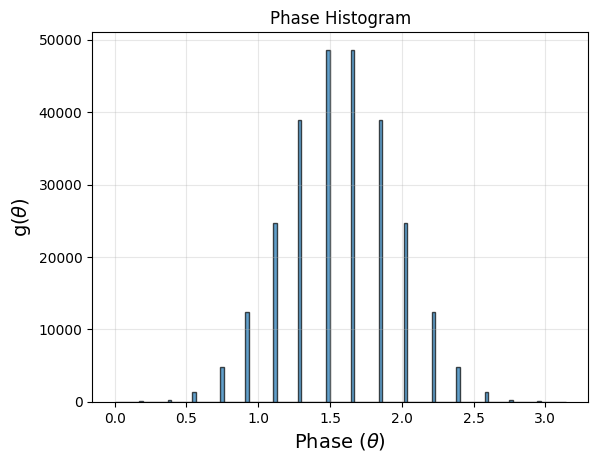

0

In [163]:
#trying for q = 14, line graph
q = 18
adj_q = adj_line(q)
Q_18 = QuantumSystem(q, adj_q)

iter50 = Q_18.psi_iter_m(50)
phases_18 = Q_18.phases(q, adj_q).reshape(-1)

Q_18.G_theta_hist(phases_18)


In [181]:
p= phases_18[phases_18 > 2.9]
# p[p < 2.57][:1000]
p.shape




(36,)

In [ ]:
#triangular mesh
q = 12
adj_list = [[0,1],[1,2],[2,3],[4,5],[5,6],[6,7],[8,9],[9,10],[10,11],[0,4],[1,4],[1,5],[2,5],[2,6],[3,6],[3,7],[4,8],[4,9],[5,9],[5,10],[6,10],[6,11],[7,11]]
adj_triangular_mesh12 = sparse_to_dense(q, adj_list)

Q_triangular_mesh = QuantumSystem(q, adj_triangular_mesh12)
phases = Q_triangular_mesh.phases(q, adj_triangular_mesh12)
iter50 = Q_triangular_mesh.psi_iter_m(50)
f_list = Q_triangular_mesh.sorted_binaries(iter50)

# print(len(f_list))
# print(f_list)

print(len(phases))
print((sorted(phases))[:2**6])

4096
[0.0, 0.0, 0.2731819698773733, 0.2731819698773733, 0.2731819698773733, 0.2731819698773733, 0.40977295481605996, 0.40977295481605996, 0.40977295481605996, 0.40977295481605996, 0.40977295481605996, 0.40977295481605996, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.5463639397547466, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332, 0.6829549246934332

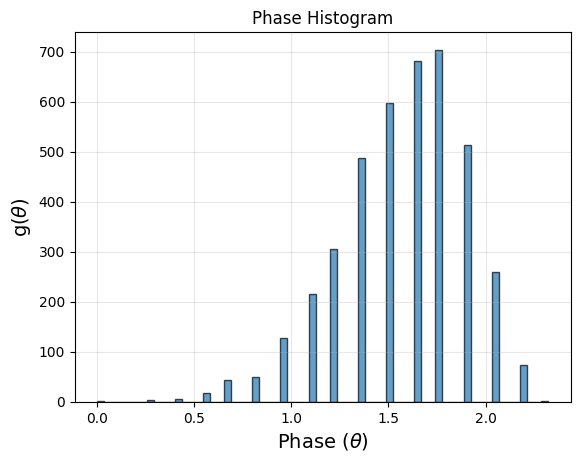

TypeError: cannot unpack non-iterable int object

In [126]:
bins, freq= Q_triangular_mesh.G_theta_hist(phases)


In [106]:
bins.shape
freq.shape

(64,)